import Library 

In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
from sklearn.svm import SVR
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, PolynomialFeatures

In [2]:
PARENT_PATH = os.path.dirname(os.getcwd())
sys.path.append(PARENT_PATH)
from config import Config

In [3]:
df = pd.read_csv(Config.PROCCESSED_GAMES_DATA_FILE)

EDA(Exploratory Data Analysis)

In [4]:
df.head()

,CpuName,CpuNumberOfCores,CpuNumberOfThreads,CpuMultiplierUnlocked,CpuTDP,CpuTurboClock,GpuName,GpuArchitecture,GpuBoostClock,GpuBus.interface,...,GpuMemoryType,GpuPixelRate,GpuNumberOfROPs,GpuShaderModel,GpuTextureRate,GpuNumberOfTransistors,GpuVulkan,GameName,GameSetting,FPS
0,Intel Core i9-9900K,8.0,16.0,1,95.0,5000.0,NVIDIA GeForce RTX 2080 Ti,Turing,1545.0,PCIe 3.0 x16,...,GDDR6,136000.0,88.0,6.5,420200.0,18600.0,1.2.131,callOfDutyWW2,med,225.3
1,Intel Core i7-9700K,8.0,8.0,1,95.0,4900.0,NVIDIA GeForce RTX 2080 Ti,Turing,1545.0,PCIe 3.0 x16,...,GDDR6,136000.0,88.0,6.5,420200.0,18600.0,1.2.131,callOfDutyWW2,med,223.3
2,Intel Core i7-8700K,6.0,12.0,1,95.0,4700.0,NVIDIA GeForce RTX 2080 Ti,Turing,1545.0,PCIe 3.0 x16,...,GDDR6,136000.0,88.0,6.5,420200.0,18600.0,1.2.131,callOfDutyWW2,med,207.3
3,Intel Core i7-7700K,4.0,8.0,1,91.0,4500.0,NVIDIA GeForce RTX 2080 Ti,Turing,1545.0,PCIe 3.0 x16,...,GDDR6,136000.0,88.0,6.5,420200.0,18600.0,1.2.131,callOfDutyWW2,med,201.3
4,Intel Core i5-9400F,6.0,6.0,0,65.0,4100.0,NVIDIA GeForce RTX 2080 Ti,Turing,1545.0,PCIe 3.0 x16,...,GDDR6,136000.0,88.0,6.5,420200.0,18600.0,1.2.131,callOfDutyWW2,med,199.2


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24624 entries, 0 to 24623
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CpuName                 24624 non-null  str    
 1   CpuNumberOfCores        24624 non-null  float64
 2   CpuNumberOfThreads      24624 non-null  float64
 3   CpuMultiplierUnlocked   24624 non-null  int64  
 4   CpuTDP                  24624 non-null  float64
 5   CpuTurboClock           24624 non-null  float64
 6   GpuName                 24624 non-null  str    
 7   GpuArchitecture         24624 non-null  str    
 8   GpuBoostClock           24624 non-null  float64
 9   GpuBus.interface        24624 non-null  str    
 10  GpuDieSize              24624 non-null  float64
 11  GpuDirectX              24624 non-null  str    
 12  GpuMemorySize           24624 non-null  float64
 13  GpuMemoryType           24624 non-null  str    
 14  GpuPixelRate            24624 non-null  float64
 

Data visualization

In [6]:
fig = px.histogram( df,x='FPS',nbins=30,title='FPS Distribution')
fig.show()

In [7]:
fig = px.scatter(df,x='GpuMemorySize',y='FPS',color='GameSetting', title='GPU Memory Size vs FPS')
fig.show()

In [8]:
fig = px.box(df, x='GameSetting',y='FPS',color='GameSetting',title='Game Settings vs FPS')
fig.show()

In [9]:
fig = px.scatter(df,x='GpuBoostClock',y='FPS',color='GameSetting',title='GPU Boost Clock vs FPS')
fig.show()

In [10]:
fig = px.scatter(df,x='GpuBus.interface',y='FPS',color='GameSetting',title='GPU Bus Interface vs FPS')
fig.show()

In [11]:
fig = px.scatter(df,x='CpuTDP',y='FPS',color='GameSetting',title='CPU TDP vs FPS')
fig.show()

In [12]:
fig = px.scatter(df,x='CpuMultiplierUnlocked',y='FPS',color='GameSetting',title='CPU Multiplier Unlocked vs FPS')
fig.show()

In [13]:
fig = px.scatter(df,x='CpuNumberOfCores',y='FPS',color='GameSetting',title='CPU Number of Cores vs FPS')
fig.show()

In [14]:
fig = px.scatter(df,x='CpuNumberOfThreads',y='FPS',color='GameSetting',title='CPU Number of Threads vs FPS')
fig.show()

In [15]:
fig = px.scatter(df,x='GpuPixelRate',y='FPS',color='GameSetting',title='GPU Pixel Rate vs FPS')
fig.show()

In [16]:
fig = px.scatter(df,x='GpuNumberOfROPs',y='FPS',color='GameSetting',title='GPU Number of ROPs vs FPS')
fig.show()

In [17]:
fig = px.scatter(df,x='GpuShaderModel',y='FPS',color='GameSetting',title='GPU Shader Model vs FPS')
fig.show()

In [18]:
fig = px.scatter(df,x='GpuTextureRate',y='FPS',color='GameSetting',title='GPU Texture Rate vs FPS')
fig.show()

In [19]:
fig = px.scatter(df,x='GpuNumberOfTransistors',y='FPS',color='GameSetting',title='GPU Number of Transistors vs FPS')
fig.show()

In [20]:
fig = px.scatter(df,x='GpuVulkan',y='FPS',color='GameSetting',title='GPU Vulkan Support vs FPS')
fig.show()

In [21]:
for col in df.select_dtypes(include='object').columns:
    print(col, df[col].unique())

CpuName <ArrowStringArray>
['Intel Core i9-9900K', 'Intel Core i7-9700K', 'Intel Core i7-8700K',
 'Intel Core i7-7700K', 'Intel Core i5-9400F', 'Intel Core i5-8600K',
  'Intel Core i5-8400', 'Intel Core i5-7600K',  'Intel Core i5-7500',
  'Intel Core i3-7100',   'AMD Ryzen 9 3900X',   'AMD Ryzen 7 3800X',
   'AMD Ryzen 7 3700X',   'AMD Ryzen 5 3600X',    'AMD Ryzen 5 3600',
   'AMD Ryzen 5 2600X',   'AMD Ryzen 5 1600X',    'AMD Ryzen 5 2600',
   'AMD Ryzen 7 1700X']
Length: 19, dtype: str
GpuName <ArrowStringArray>
[         'NVIDIA GeForce RTX 2080 Ti',             'NVIDIA GeForce RTX 2080',
          'NVIDIA GeForce GTX 1080 Ti',          'NVIDIA GeForce GTX TITAN X',
       'NVIDIA GeForce RTX 2070 SUPER',             'NVIDIA GeForce RTX 2070',
      'NVIDIA GeForce GTX 1080 11Gbps',       'NVIDIA GeForce RTX 2060 SUPER',
             'NVIDIA GeForce RTX 2060',          'NVIDIA GeForce GTX 1070 Ti',
      'NVIDIA GeForce GTX 1070 GDDR5X',          'NVIDIA GeForce GTX 1660 Ti',
     

C:\Users\clt\AppData\Local\Temp\ipykernel_18912\3255506791.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [22]:
numeric_columns = df.drop('FPS', axis=1).select_dtypes(include=np.number).columns
columns_to_drop = ['GpuName', 'CpuName']
label_columns = ['GpuBus.interface', 'GpuDirectX', 'GpuVulkan', 'GameSetting']
one_hot_columns = ['GpuArchitecture', 'GpuMemoryType', 'GameName']

df.drop(columns=columns_to_drop, inplace=True)

label_encoders = LabelEncoder()
for col in label_columns:
    df[col] = label_encoders.fit_transform(df[col])

one_hot_encoder = OneHotEncoder(sparse_output=False, drop='first')
one_hot_encoded = one_hot_encoder.fit_transform(df[one_hot_columns])
one_hot_encoded_df = pd.DataFrame(one_hot_encoded, columns=one_hot_encoder.get_feature_names_out(one_hot_columns))
df = pd.concat([df.reset_index(), one_hot_encoded_df], axis=1).drop(columns=one_hot_columns)

In [23]:
X = df.drop('FPS', axis=1)
y = df['FPS']

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

In [26]:
from sklearn.preprocessing import FunctionTransformer
import numpy as np

log_transformer = FunctionTransformer(np.log1p)

y_train = log_transformer.fit_transform(y_train)
y_test = log_transformer.transform(y_test)

In [ ]:
models = {
    "XGB": XGBRegressor(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8),
    "DT": DecisionTreeRegressor(max_depth=10),
    "RF": RandomForestRegressor( 
        n_estimators=400,
        max_depth=15,
        min_samples_split=5),
    "LR": LinearRegression(),
    "SVM": SVR(
        kernel='rbf',
        C=100, 
        gamma=0.1),
    "KNN": KNeighborsRegressor(
        n_neighbors=7,
        weights='distance')
}

for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    print(name, r2_score(y_test, pred))

XGB 0.9992963107519502
DT 0.8664878259245266
RF 0.97619188705736
LR 0.9737654189360678
SVM 0.9208351953295173
KNN 0.9524528106416813


In [28]:
from sklearn.model_selection import cross_val_score

for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring='r2')
    print(name, "CV Score:", scores.mean())

XGB CV Score: 0.9992220179436391
DT CV Score: 0.8657859603233844
RF CV Score: 0.9757677518769142
LR CV Score: 0.9737109968463684
SVM CV Score: 0.8976981837516217
KNN CV Score: 0.9482454671465552


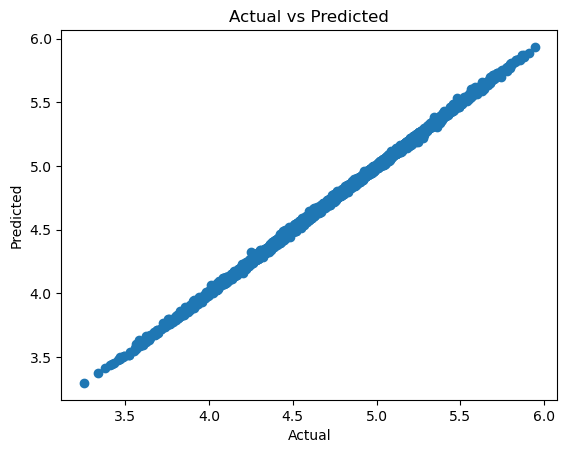

In [29]:
plt.scatter(y_test, models["XGB"].predict(X_test))
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

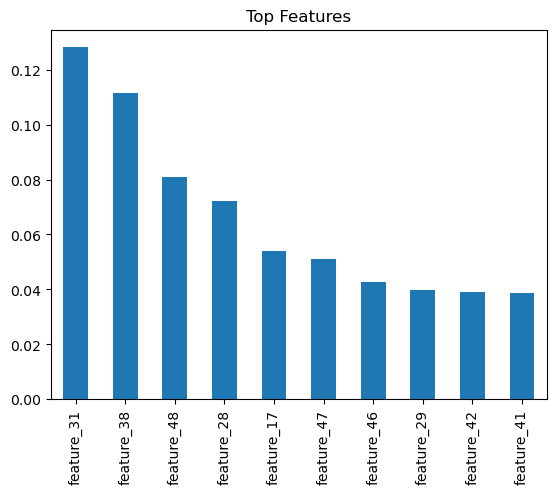

In [30]:
feat_names = [f"feature_{i}" for i in range(len(models["XGB"].feature_importances_))]

feat_imp = pd.Series(
    models["XGB"].feature_importances_,
    index=feat_names
).sort_values(ascending=False)

feat_imp.head(10).plot(kind='bar')
plt.title("Top Features")
plt.show()

In [31]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()

model.fit(X_train_poly, y_train)
model.predict(X_test_poly)

print(r2_score(y_test, model.predict(X_test_poly)))

0.9993465221121197
